In [1]:
import os, sys, json, time, math, random, glob, platform, subprocess, zipfile, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
if DEVICE == 'cpu':
    print('PERINGATAN: GPU tidak aktif. Aktifkan Runtime > Change runtime type > GPU.')
OUT_DIR = '/content/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.precision', 3)

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
Device: cuda Tesla T4


In [2]:
import os, glob, shutil, zipfile
from google.colab import files

DATA_DIR = '/content/data'
NEEDED = ['rul_train.csv.gz', 'rul_test.csv.gz']
os.makedirs(DATA_DIR, exist_ok=True)

def _rapikan_upload():
    for f in NEEDED:
        tujuan = os.path.join(DATA_DIR, f)
        if os.path.exists(f) and not os.path.exists(tujuan):
            shutil.move(f, tujuan)

    for zp in glob.glob('*.zip'):
        with zipfile.ZipFile(zp) as z:
            for f in NEEDED:
                if f in z.namelist() and not os.path.exists(os.path.join(DATA_DIR, f)):
                    z.extract(f, DATA_DIR)

def _kurang():
    return [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]

_rapikan_upload()
if _kurang():
    print('Silakan upload file berikut:', _kurang())
    uploaded = files.upload()
    _rapikan_upload()
assert not _kurang(), f'Masih kurang: {_kurang()} -> jalankan sel ini lagi dan upload file tersebut'
for f in NEEDED:
    print(f'{f:20s} {os.path.getsize(os.path.join(DATA_DIR, f))/1e6:6.1f} MB')

Silakan upload file berikut: ['rul_train.csv.gz', 'rul_test.csv.gz']


Saving rul_test.csv.gz to rul_test.csv.gz
Saving rul_train.csv.gz to rul_train.csv.gz
rul_train.csv.gz       20.3 MB
rul_test.csv.gz         4.1 MB


In [3]:
QUICK = False

RUL_CAP = 150
CFG = dict(
    W          = 40,
    epochs     = 4 if QUICK else 30,
    spe        = 20000 if QUICK else 60000,
    batch      = 512,
    lr         = 2e-3,
    wd         = 1e-4,
    hidden     = 64,
    dropout    = 0.2,
)
CMP_SEEDS = [0] if QUICK else [0, 1, 2]
N_ENS     = 2 if QUICK else 5
MC_T      = 10 if QUICK else 30
N_CUTS    = 5
SPLIT_SEED = 42

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print(CFG)

{'W': 40, 'epochs': 30, 'spe': 60000, 'batch': 512, 'lr': 0.002, 'wd': 0.0001, 'hidden': 64, 'dropout': 0.2}


In [4]:
tr = pd.read_csv(f'{DATA_DIR}/rul_train.csv.gz').sort_values(['id_unit', 'siklus']).reset_index(drop=True)
te = pd.read_csv(f'{DATA_DIR}/rul_test.csv.gz').sort_values(['id_unit', 'siklus']).reset_index(drop=True)
SET = ['setel_1', 'setel_2', 'setel_3']
SEN = [f's{i:02d}' for i in range(1, 22)]

for nm, df in [('train', tr), ('test', te)]:
    g = df.groupby('id_unit')['siklus']
    print(f"{nm}: {df.shape}, mesin={df['id_unit'].nunique()}, mulai dari 1: {(g.min() == 1).all()}, "
          f"tanpa celah: {(g.diff().dropna() == 1).all()}")
print('ID mesin train & test beririsan:', len(set(tr.id_unit) & set(te.id_unit)))
tr.head()

train: (254174, 26), mesin=900, mulai dari 1: True, tanpa celah: True
test: (51692, 26), mesin=300, mulai dari 1: True, tanpa celah: True
ID mesin train & test beririsan: 0


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,3,1,20.001,0.701,100.0,1107.746,569.289,991.700,1099.533,NaN,...,1092.248,1144.779,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003
1,3,2,34.996,0.842,100.0,1071.040,587.821,1013.673,NaN,157.684,...,1095.511,1167.320,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368
2,3,3,0.001,-0.001,100.0,1130.132,585.094,998.221,1127.436,161.918,...,1091.245,1170.340,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443
3,3,4,35.001,0.838,100.0,1080.962,585.775,1016.998,1152.147,NaN,...,1096.911,1173.207,1348.423,877.459,784.038,399.505,978.649,813.737,1113.184,411.554
4,3,5,9.998,0.248,100.0,1095.013,580.506,997.108,1119.245,169.359,...,1102.956,1159.881,1341.195,872.265,772.284,NaN,950.568,821.425,969.681,362.551


## (a) Eksplorasi & preprocessing
### a.1 Panjang riwayat

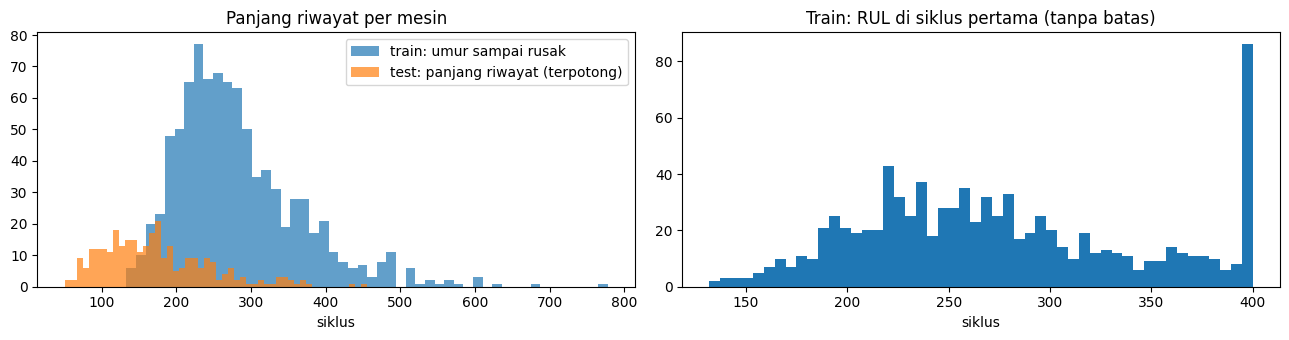

Umur train   : {'count': 900.0, 'mean': 282.4, 'std': 84.6, 'min': 133.0, '25%': 224.0, '50%': 265.0, '75%': 323.0, 'max': 778.0}
Panjang test : {'count': 300.0, 'mean': 172.3, 'std': 72.7, 'min': 50.0, '25%': 117.0, '50%': 162.5, '75%': 212.0, 'max': 455.0}


In [5]:
life = tr.groupby('id_unit')['siklus'].max()
tlen = te.groupby('id_unit')['siklus'].max()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(life, bins=50, alpha=.7, label='train: umur sampai rusak'); ax[0].hist(tlen, bins=50, alpha=.7, label='test: panjang riwayat (terpotong)')
ax[0].set_xlabel('siklus'); ax[0].legend(); ax[0].set_title('Panjang riwayat per mesin')
ax[1].hist(np.minimum(life - 1, 400), bins=50); ax[1].set_title('Train: RUL di siklus pertama (tanpa batas)'); ax[1].set_xlabel('siklus')
plt.tight_layout(); plt.show()
print('Umur train   :', life.describe().round(1).to_dict())
print('Panjang test :', tlen.describe().round(1).to_dict())

### a.2 Pengaruh setelan operasi
Tiga setelan operasi membentuk beberapa **kondisi operasi (regime)** diskret. Sensor sangat bergantung pada regime, sehingga sinyal mentah satu mesin terlihat "zig-zag" dan tren degradasi tertutup.

Regime: {'0_100': 0, '10_100': 1, '20_100': 2, '25_60': 3, '35_100': 4, '42_100': 5}
regime      0      1      2      3      4      5
train   0.167  0.166  0.168  0.166  0.166  0.168
test    0.166  0.165  0.167  0.165  0.167  0.170


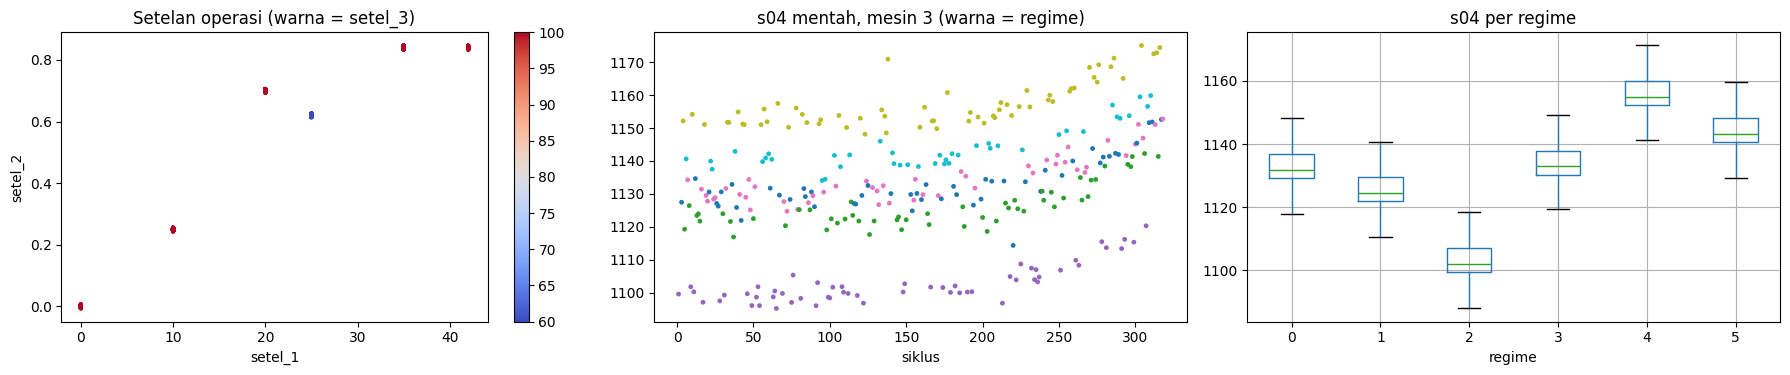

Porsi variasi sensor yang BUKAN karena regime (kecil = sangat dipengaruhi setelan):
                                s01  s02   s03    s04    s05    s06    s07    s08    s09    s10    s11    s12    s13    s14    s15    s16    s17   s18    s19    s20    s21
std dalam-regime / std total  0.244  0.2  0.29  0.372  0.013  0.495  0.705  0.555  0.067  0.082  0.791  0.256  0.321  0.397  0.766  0.134  0.245  0.06  0.047  0.093  0.026


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sc = ax[0].scatter(tr.setel_1[::20], tr.setel_2[::20], c=tr.setel_3[::20], s=4, cmap='coolwarm')
ax[0].set_xlabel('setel_1'); ax[0].set_ylabel('setel_2'); ax[0].set_title('Setelan operasi (warna = setel_3)'); plt.colorbar(sc, ax=ax[0])

def regime_key(df):
    return df['setel_1'].round(0).astype(int).astype(str) + '_' + df['setel_3'].round(0).astype(int).astype(str)
REG_LIST = sorted(regime_key(tr).unique())
REG_MAP = {k: i for i, k in enumerate(REG_LIST)}
N_REG = len(REG_LIST)
tr['regime'] = regime_key(tr).map(REG_MAP)
te['regime'] = regime_key(te).map(REG_MAP)
assert te['regime'].notna().all(), 'ada regime test yang tidak ada di train'
print('Regime:', REG_MAP)
print(pd.DataFrame({'train': tr.regime.value_counts(normalize=True).sort_index(),
                    'test': te.regime.value_counts(normalize=True).sort_index()}).round(3).T)

u = tr.id_unit.iloc[0]; d = tr[tr.id_unit == u]
ax[1].scatter(d.siklus, d.s04, c=d.regime, cmap='tab10', s=6); ax[1].set_title(f's04 mentah, mesin {u} (warna = regime)'); ax[1].set_xlabel('siklus')
tr.boxplot(column='s04', by='regime', ax=ax[2], showfliers=False); ax[2].set_title('s04 per regime'); plt.suptitle('')
plt.tight_layout(); plt.show()

ratio = (tr.groupby('regime')[SEN].std().mean() / tr[SEN].std()).rename('std dalam-regime / std total')
print('Porsi variasi sensor yang BUKAN karena regime (kecil = sangat dipengaruhi setelan):')
print(ratio.round(3).to_frame().T.to_string())

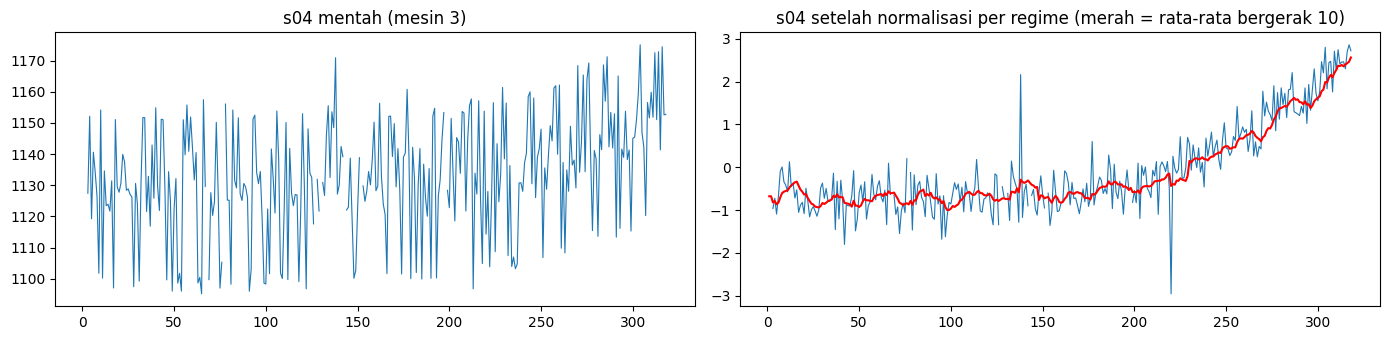

In [7]:
tr['rul_raw'] = tr.groupby('id_unit')['siklus'].transform('max') - tr['siklus']

def fit_reg_stats(df):
    g = df.groupby('regime')[SEN]
    return g.mean(), g.std()

def norm_regime(df, mu, sd):
    out = df[SEN].copy()
    m, s = mu.loc[df['regime']].values, sd.loc[df['regime']].values
    return pd.DataFrame((out.values - m) / s, columns=SEN, index=df.index)

mu_all, sd_all = fit_reg_stats(tr)
Z = norm_regime(tr, mu_all, sd_all)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].plot(d.siklus, d.s04, lw=.8); ax[0].set_title(f's04 mentah (mesin {u})')
ax[1].plot(d.siklus, Z.loc[d.index, 's04'], lw=.8); ax[1].plot(d.siklus, Z.loc[d.index, 's04'].rolling(10, min_periods=1).mean(), 'r')
ax[1].set_title('s04 setelah normalisasi per regime (merah = rata-rata bergerak 10)')
plt.tight_layout(); plt.show()

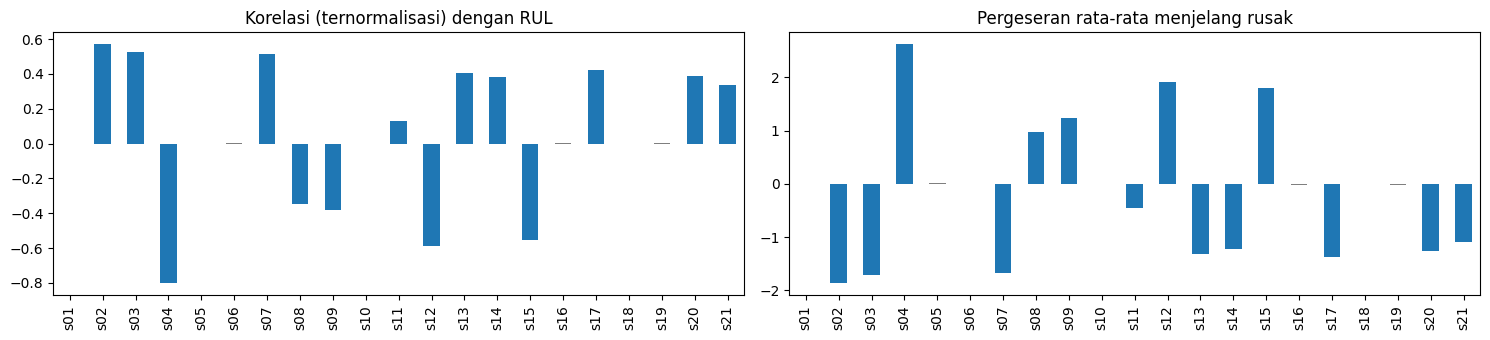

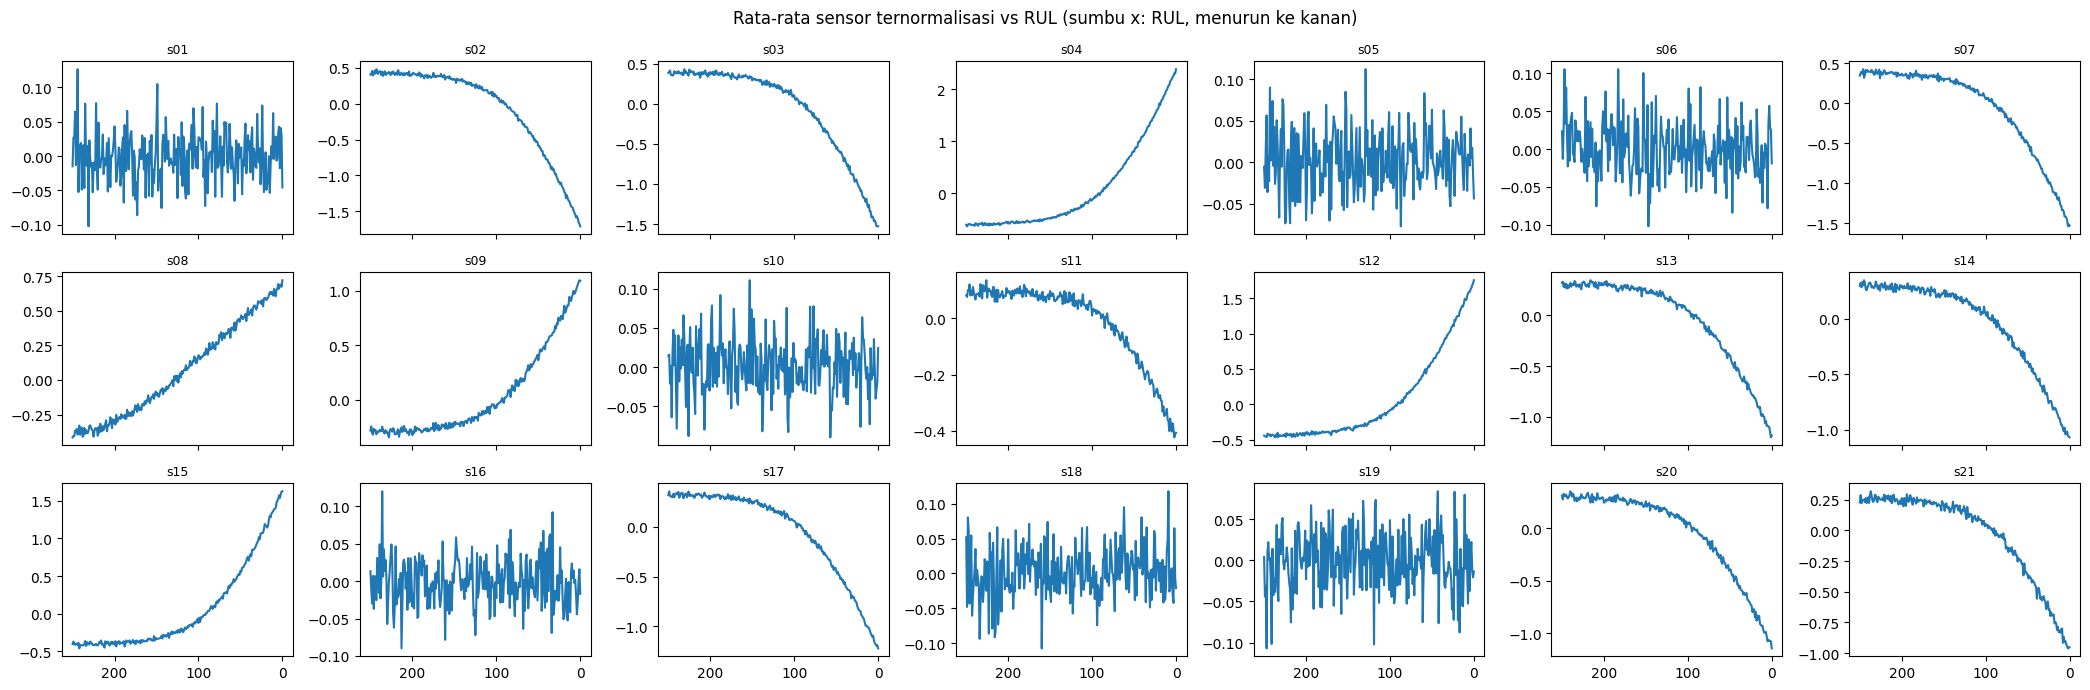

,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
korelasi dg RUL,-0.001,0.570,0.524,-0.803,-0.003,0.003,0.514,-0.349,-0.384,0.000,...,-0.587,0.403,0.381,-0.552,0.002,0.424,-0.005,0.002,0.389,0.338
pergeseran akhir umur (std),0.001,-1.869,-1.717,2.621,0.008,-0.011,-1.680,0.973,1.235,-0.002,...,1.916,-1.307,-1.222,1.800,-0.013,-1.373,0.005,-0.014,-1.255,-1.095


In [8]:
rul_c = tr['rul_raw'].clip(upper=RUL_CAP)
corr = Z.corrwith(rul_c)
trend = Z[tr.rul_raw < 20].mean() - Z[tr.rul_raw > RUL_CAP].mean()
info = pd.DataFrame({'korelasi dg RUL': corr, 'pergeseran akhir umur (std)': trend})
fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
info['korelasi dg RUL'].plot.bar(ax=ax[0], color=np.where(corr.abs() >= 0.05, 'tab:blue', 'tab:gray')); ax[0].set_title('Korelasi (ternormalisasi) dengan RUL')
info['pergeseran akhir umur (std)'].plot.bar(ax=ax[1], color=np.where(trend.abs() >= 0.2, 'tab:blue', 'tab:gray')); ax[1].set_title('Pergeseran rata-rata menjelang rusak')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 7, figsize=(21, 7), sharex=True)
grp = Z.assign(r=tr.rul_raw).query('r <= 250').groupby('r')[SEN].mean()
for k, s in enumerate(SEN):
    a = ax[k // 7, k % 7]; a.plot(grp.index, grp[s]); a.invert_xaxis(); a.set_title(s, fontsize=9)
plt.suptitle('Rata-rata sensor ternormalisasi vs RUL (sumbu x: RUL, menurun ke kanan)'); plt.tight_layout(); plt.show()
display(info.round(3).T)

,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
train,2.00%,2.07%,2.01%,2.05%,2.01%,2.06%,2.05%,2.02%,2.04%,2.02%,1.98%,2.04%,2.03%,1.99%,2.02%,2.00%,2.01%,2.06%,2.03%,2.11%,1.97%
test,2.01%,1.95%,2.04%,2.09%,2.02%,2.02%,2.00%,1.95%,1.98%,2.14%,1.98%,1.89%,1.95%,1.95%,1.97%,1.99%,2.10%,1.92%,2.04%,1.96%,2.06%


Baris dengan >=1 sensor hilang: train 35.03%, test 34.63%
Proporsi nilai hilang menurut RUL (cek apakah hilangnya acak):
rul_raw
(-1.0, 25.0]             0.02
(25.0, 50.0]             0.02
(50.0, 100.0]            0.02
(100.0, 150.0]           0.02
(150.0, 1000000000.0]    0.02

Proporsi titik lonjakan (|z robust| > 6) per sensor:
             s01        s02        s03        s04    s05    s06        s07        s08        s09        s10        s11        s12        s13        s14        s15    s16        s17    s18    s19    s20        s21
spike  9.000e-04  9.500e-04  8.900e-04  8.700e-04  0.001  0.001  8.900e-04  7.800e-04  8.600e-04  8.900e-04  8.100e-04  8.300e-04  9.400e-04  9.600e-04  9.100e-04  0.001  9.700e-04  0.001  0.001  0.001  9.700e-04


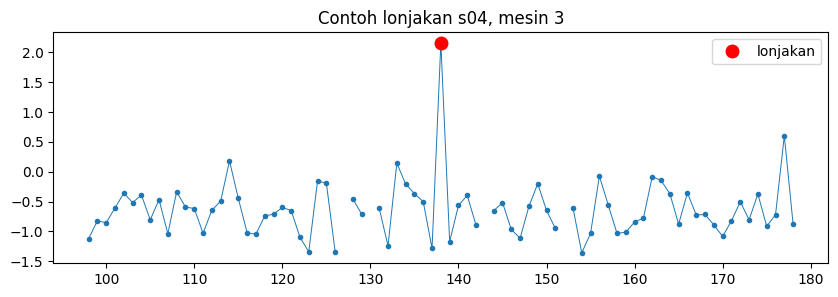

In [9]:
miss = pd.DataFrame({'train': tr[SEN].isna().mean(), 'test': te[SEN].isna().mean()}).T
display(miss.style.format('{:.2%}'))
print('Baris dengan >=1 sensor hilang: train %.2f%%, test %.2f%%' % (100 * tr[SEN].isna().any(axis=1).mean(), 100 * te[SEN].isna().any(axis=1).mean()))
rul_bin = pd.cut(tr.rul_raw, [-1, 25, 50, 100, 150, 1e9])
print('Proporsi nilai hilang menurut RUL (cek apakah hilangnya acak):')
print(tr[SEN].isna().mean(axis=1).groupby(rul_bin).mean().round(4).to_string())

K_MED = 10
med_prev = Z.groupby(tr['id_unit']).transform(lambda x: x.shift(1).rolling(K_MED, min_periods=3).median())
res = Z - med_prev
sig = res.abs().median() * 1.4826
rz = res / sig
print('\nProporsi titik lonjakan (|z robust| > 6) per sensor:')
print((rz.abs() > 6).mean().round(5).to_frame('spike').T.to_string())

s_ex = 's04'; ex = np.where(rz[s_ex].abs() > 6)[0][0]; uu = tr.id_unit.iloc[ex]
dd = tr.index[(tr.id_unit == uu)]
w = dd[(dd >= ex - 40) & (dd <= ex + 40)]
plt.figure(figsize=(10, 3)); plt.plot(tr.siklus[w], Z.loc[w, s_ex], '.-', lw=.7)
plt.plot(tr.siklus[ex], Z.loc[ex, s_ex], 'ro', ms=9, label='lonjakan')
plt.title(f'Contoh lonjakan {s_ex}, mesin {uu}'); plt.legend(); plt.show()

mesin latih: 720 | mesin validasi: 180


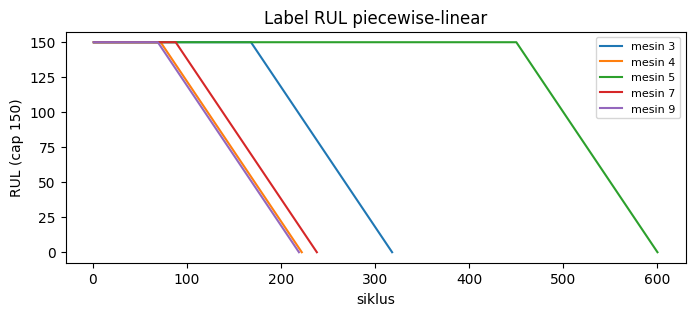

In [10]:
tr['rul'] = tr['rul_raw'].clip(upper=RUL_CAP).astype(np.float32)
units = tr['id_unit'].unique()
rng = np.random.default_rng(SPLIT_SEED)
units_va = np.sort(rng.choice(units, size=int(0.2 * len(units)), replace=False))
units_tr = np.setdiff1d(units, units_va)
print('mesin latih:', len(units_tr), '| mesin validasi:', len(units_va))

fig, ax = plt.subplots(figsize=(8, 3))
for uid in units[:5]:
    q = tr[tr.id_unit == uid]; ax.plot(q.siklus, q.rul, label=f'mesin {uid}')
ax.set_xlabel('siklus'); ax.set_ylabel('RUL (cap 150)'); ax.set_title('Label RUL piecewise-linear'); ax.legend(fontsize=8); plt.show()

In [11]:
def fit_prep(df_fit):
    mu, sd = fit_reg_stats(df_fit)
    z = norm_regime(df_fit, mu, sd)
    corr = z.corrwith(df_fit['rul_raw'].clip(upper=RUL_CAP))
    sel = [s for s in SEN if abs(corr[s]) >= 0.05]
    mp = z.groupby(df_fit['id_unit'].values).transform(lambda x: x.shift(1).rolling(K_MED, min_periods=3).median())
    sig = ((z - mp).abs().median() * 1.4826)
    return dict(mu=mu, sd=sd, sel=sel, sig=sig)

def transform(df, P):
    z = norm_regime(df, P['mu'], P['sd'])[P['sel']]
    gid = df['id_unit'].values
    mp = z.groupby(gid).transform(lambda x: x.shift(1).rolling(K_MED, min_periods=3).median())
    spike = ((z - mp).abs() > 6 * P['sig'][P['sel']]) & mp.notna()
    z = z.mask(spike, mp)
    z = z.groupby(gid).ffill().fillna(0.0)
    oh = np.eye(N_REG, dtype=np.float32)[df['regime'].values.astype(int)]
    X = np.concatenate([z.values.astype(np.float32), oh, (df['siklus'].values / 300.0)[:, None].astype(np.float32)], 1)
    start = df.groupby('id_unit').cumcount().values
    start = (np.arange(len(df)) - start).astype(np.int64)
    return X, start, int(spike.values.sum())

t0 = time.time()
P_val = fit_prep(tr[tr.id_unit.isin(units_tr)])
X_all, START_all, nsp = transform(tr, P_val)
FEATS = P_val['sel'] + [f'regime_{i}' for i in range(N_REG)] + ['siklus/300']
N_FEAT = X_all.shape[1]
print(f'Sensor terpilih ({len(P_val["sel"])}):', P_val['sel'])
print('Sensor dibuang:', [s for s in SEN if s not in P_val['sel']])
print(f'Lonjakan diganti: {nsp} | jumlah fitur: {N_FEAT} | waktu {time.time()-t0:.1f}s')
assert not np.isnan(X_all).any()
Y_all = tr['rul'].values.astype(np.float32)
UNIT_all = tr['id_unit'].values

Sensor terpilih (14): ['s02', 's03', 's04', 's07', 's08', 's09', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Sensor dibuang: ['s01', 's05', 's06', 's10', 's16', 's18', 's19']
Lonjakan diganti: 3239 | jumlah fitur: 21 | waktu 8.1s


In [12]:
W = CFG['W']

def window_np(X, start, ends):
    idx = ends[:, None] - (W - 1) + np.arange(W)[None, :]
    idx = np.maximum(idx, start[ends][:, None])
    return X[idx]

_e = np.random.default_rng(0).choice(len(X_all), 5000, replace=False)
_idx = np.maximum(_e[:, None] - (W - 1) + np.arange(W)[None, :], START_all[_e][:, None])
assert (UNIT_all[_idx] == UNIT_all[_e][:, None]).all() and (_idx <= _e[:, None]).all()
print('Cek window OK: semua indeks berasal dari mesin yang sama dan tidak melewati ujung window.')

rows_tr = np.where(np.isin(UNIT_all, units_tr))[0]
rows_va = np.where(np.isin(UNIT_all, units_va))[0]

def make_cuts(units_sel, n_cuts, seed):
    r = np.random.default_rng(seed); ends = []
    for uid in units_sel:
        rows = np.where(UNIT_all == uid)[0]
        L = len(rows)
        lo = min(50, L - 1)
        c = r.integers(lo, L, size=n_cuts)
        ends.extend(rows[c - 1])
    return np.array(ends)

cuts_va = make_cuts(units_va, N_CUTS, SPLIT_SEED)
y_cuts = Y_all[cuts_va]
print('Titik evaluasi validasi:', len(cuts_va), '| RUL aktual:', pd.Series(y_cuts).describe().round(1).to_dict())

Cek window OK: semua indeks berasal dari mesin yang sama dan tidak melewati ujung window.
Titik evaluasi validasi: 900 | RUL aktual: {'count': 900.0, 'mean': 95.3, 'std': 50.4, 'min': 1.0, '25%': 49.0, '50%': 100.0, '75%': 150.0, 'max': 150.0}


In [13]:
RANGES = [(0, 30), (30, 60), (60, 100), (100, 151)]

def asym_score(pred, true):
    d = pred - true
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

def metrics(pred, true):
    pred = np.clip(pred, 0, RUL_CAP)
    r = dict(RMSE=float(np.sqrt(np.mean((pred - true) ** 2))),
             score_rata2=float(asym_score(pred, true).mean()),
             score_per300=float(asym_score(pred, true).mean() * 300),
             bias=float(np.mean(pred - true)))
    for lo, hi in RANGES:
        m = (true >= lo) & (true < hi)
        r[f'RMSE[{lo},{min(hi,150)}]'] = float(np.sqrt(np.mean((pred[m] - true[m]) ** 2))) if m.any() else np.nan
        r[f'score[{lo},{min(hi,150)}]'] = float(asym_score(pred[m], true[m]).mean()) if m.any() else np.nan
    return r

RES = {}

In [14]:
def window_features(X, start, ends):
    w = window_np(X, start, ends)
    ns = len(P_val['sel'])
    s = w[:, :, :ns]
    t = np.arange(W, dtype=np.float32); t = t - t.mean()
    slope = (s * t[None, :, None]).sum(1) / (t ** 2).sum()
    return np.concatenate([s[:, -1], s.mean(1), slope, s.min(1), s.max(1), w[:, -1, ns:]], 1)

rb = np.random.default_rng(0).choice(rows_tr, min(len(rows_tr), 80000), replace=False)
t0 = time.time()
gbr = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=0)
gbr.fit(window_features(X_all, START_all, rb), Y_all[rb])
pred_gb = np.clip(gbr.predict(window_features(X_all, START_all, cuts_va)), 0, RUL_CAP)
RES['baseline_GBR'] = metrics(pred_gb, y_cuts)
print(f'GBR selesai {time.time()-t0:.0f}s ->', {k: round(v, 3) for k, v in list(RES["baseline_GBR"].items())[:4]})

GBR selesai 20s -> {'RMSE': 19.528, 'score_rata2': 24.969, 'score_per300': 7490.561, 'bias': 3.24}


In [15]:
class GRUNet(nn.Module):
    def __init__(self, f, h=64, dp=0.2):
        super().__init__()
        self.rnn = nn.GRU(f, h, num_layers=2, batch_first=True, dropout=dp)
        self.head = nn.Sequential(nn.Dropout(dp), nn.Linear(h, 32), nn.ReLU(), nn.Dropout(dp), nn.Linear(32, 1))
    def forward(self, x):
        o, _ = self.rnn(x)
        return self.head(o[:, -1]).squeeze(-1)

class TCNBlock(nn.Module):
    def __init__(self, cin, cout, k, dil, dp):
        super().__init__()
        self.pad = (k - 1) * dil
        self.c1 = nn.Conv1d(cin, cout, k, dilation=dil)
        self.c2 = nn.Conv1d(cout, cout, k, dilation=dil)
        self.dp = nn.Dropout(dp)
        self.down = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x):
        y = self.dp(F.relu(self.c1(F.pad(x, (self.pad, 0)))))
        y = self.dp(F.relu(self.c2(F.pad(y, (self.pad, 0)))))
        return F.relu(y + self.down(x))

class TCNNet(nn.Module):
    def __init__(self, f, h=64, dp=0.2):
        super().__init__()
        self.net = nn.Sequential(*[TCNBlock(f if i == 0 else h, h, 3, 2 ** i, dp) for i in range(4)])
        self.head = nn.Sequential(nn.Dropout(dp), nn.Linear(h, 32), nn.ReLU(), nn.Dropout(dp), nn.Linear(32, 1))
    def forward(self, x):
        y = self.net(x.transpose(1, 2))
        return self.head(y[:, :, -1]).squeeze(-1)

class TransNet(nn.Module):
    def __init__(self, f, h=64, dp=0.2, w=40):
        super().__init__()
        self.inp = nn.Linear(f, h)
        self.pos = nn.Parameter(torch.randn(1, w, h) * 0.02)
        layer = nn.TransformerEncoderLayer(h, 4, 2 * h, dropout=dp, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(h)
        self.head = nn.Sequential(nn.Dropout(dp), nn.Linear(2 * h, 32), nn.ReLU(), nn.Dropout(dp), nn.Linear(32, 1))
    def forward(self, x):
        z = self.norm(self.enc(self.inp(x) + self.pos[:, :x.shape[1]]))
        return self.head(torch.cat([z[:, -1], z.mean(1)], 1)).squeeze(-1)

ARCHS = {'GRU': GRUNet, 'TCN': TCNNet, 'Transformer': TransNet}
def make_model(arch):
    if arch == 'Transformer':
        return TransNet(N_FEAT, CFG['hidden'], CFG['dropout'], W)
    return ARCHS[arch](N_FEAT, CFG['hidden'], CFG['dropout'])

for a in ARCHS:
    print(f'{a:12s} params: {sum(p.numel() for p in make_model(a).parameters()):,}')

GRU          params: 43,777
TCN          params: 94,081
Transformer  params: 75,201


In [16]:
AR = torch.arange(W, device=DEVICE)

def to_dev(X, start, y=None):
    D = dict(X=torch.from_numpy(X).to(DEVICE), start=torch.from_numpy(start).to(DEVICE))
    if y is not None: D['y'] = torch.from_numpy(y).to(DEVICE)
    return D

def gather(D, e):
    idx = e[:, None] - (W - 1) + AR[None, :]
    idx = torch.maximum(idx, D['start'][e][:, None])
    return D['X'][idx]

@torch.no_grad()
def predict(model, D, ends, mc=0, bs=4096):
    e_all = torch.as_tensor(ends, device=DEVICE)
    def once():
        out = []
        for i in range(0, len(e_all), bs):
            out.append(model(gather(D, e_all[i:i + bs])).float())
        return (torch.cat(out) * RUL_CAP).clamp(0, RUL_CAP).cpu().numpy()
    if mc == 0:
        model.eval(); return once()
    model.train()
    s = np.stack([once() for _ in range(mc)]); model.eval(); return s

def train_model(arch, D, rows, seed, cfg=CFG, val=None, verbose=True, tag=''):
    set_seed(seed)
    model = make_model(arch).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    steps = cfg['spe'] // cfg['batch']
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=cfg['epochs'] * steps, pct_start=0.2)
    gen = torch.Generator().manual_seed(seed)
    rows_t = torch.as_tensor(rows)
    hist, t0 = [], time.time()
    for ep in range(cfg['epochs']):
        model.train(); tot = 0.0
        sel = rows_t[torch.randint(len(rows_t), (steps * cfg['batch'],), generator=gen)].to(DEVICE)
        for s in range(steps):
            e = sel[s * cfg['batch']:(s + 1) * cfg['batch']]
            pred = model(gather(D, e))
            loss = F.mse_loss(pred, D['y'][e] / RUL_CAP)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); tot += loss.item()
        h = dict(epoch=ep + 1, train_RMSE=math.sqrt(tot / steps) * RUL_CAP)
        if val is not None:
            pv = predict(model, D, val[0])
            h['val_RMSE'] = float(np.sqrt(np.mean((pv - val[1]) ** 2)))
            h['val_score'] = float(asym_score(pv, val[1]).mean())
        hist.append(h)
        if verbose and (ep == 0 or (ep + 1) % 10 == 0 or ep + 1 == cfg['epochs']):
            print(f'  [{tag or arch} s{seed}] ep {ep+1:2d} ' + ' '.join(f'{k}={v:.2f}' for k, v in h.items() if k != 'epoch') + f' ({time.time()-t0:.0f}s)')
    return model, pd.DataFrame(hist)

D_val = to_dev(X_all, START_all, Y_all)

### Sanity check: overfit satu batch

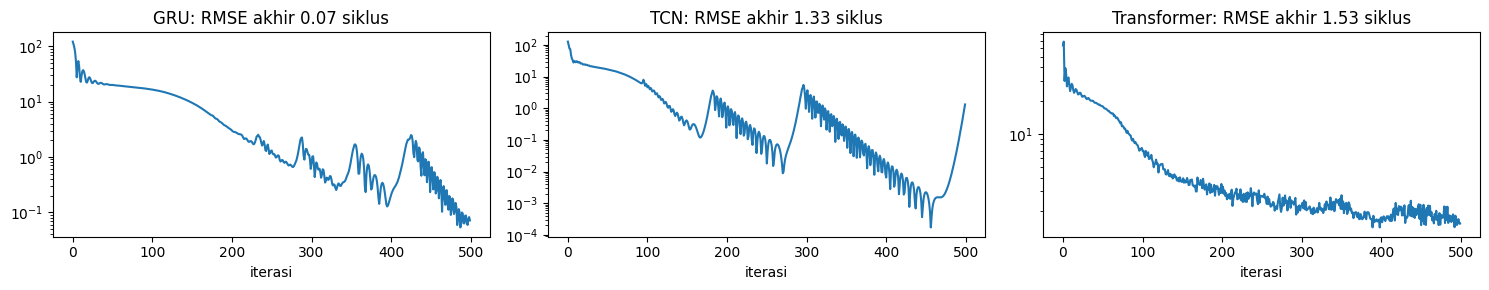

In [17]:
set_seed(0)
e = torch.as_tensor(rows_tr[np.random.default_rng(1).choice(len(rows_tr), 256, replace=False)], device=DEVICE)
xb, yb = gather(D_val, e), D_val['y'][e] / RUL_CAP
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for k, a in enumerate(ARCHS):
    m = make_model(a).to(DEVICE)
    for mod in m.modules():
        if isinstance(mod, nn.Dropout): mod.p = 0.0
    if a == 'GRU': m.rnn.dropout = 0.0
    opt = torch.optim.Adam(m.parameters(), lr=3e-3); ls = []
    for it in range(500):
        m.train(); loss = F.mse_loss(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step(); ls.append(math.sqrt(loss.item()) * RUL_CAP)
    ax[k].semilogy(ls); ax[k].set_title(f'{a}: RMSE akhir {ls[-1]:.2f} siklus'); ax[k].set_xlabel('iterasi')
plt.tight_layout(); plt.show()

### Perbandingan arsitektur (validasi per mesin, beberapa seed)

In [18]:
MODELS, HISTS, PRED_CMP = {}, {}, {}
for a in ARCHS:
    preds = []
    for s in CMP_SEEDS:
        m, h = train_model(a, D_val, rows_tr, s, val=(cuts_va, y_cuts))
        MODELS[(a, s)] = m; HISTS[(a, s)] = h
        p = predict(m, D_val, cuts_va); preds.append(p)
        RES[f'{a}_seed{s}'] = metrics(p, y_cuts)
    PRED_CMP[a] = preds

rows = []
for a in ['baseline_GBR'] + list(ARCHS):
    if a == 'baseline_GBR':
        r = RES[a]; rows.append({'model': a, **{k: f'{r[k]:.2f}' for k in ['RMSE', 'score_rata2', 'score_per300', 'bias']}})
    else:
        df = pd.DataFrame([RES[f'{a}_seed{s}'] for s in CMP_SEEDS])
        rows.append({'model': a, **{k: f'{df[k].mean():.2f} ± {df[k].std(ddof=0):.2f}' for k in ['RMSE', 'score_rata2', 'score_per300', 'bias']}})
cmp_df = pd.DataFrame(rows).set_index('model')
display(cmp_df)

BEST = min(ARCHS, key=lambda a: np.mean([RES[f'{a}_seed{s}']['RMSE'] for s in CMP_SEEDS]))
print('Arsitektur terbaik (RMSE validasi rata-rata):', BEST)

  [GRU s0] ep  1 train_RMSE=88.32 val_RMSE=27.27 val_score=84.70 (1s)
  [GRU s0] ep 10 train_RMSE=20.97 val_RMSE=19.03 val_score=19.24 (5s)
  [GRU s0] ep 20 train_RMSE=17.83 val_RMSE=18.78 val_score=15.14 (11s)
  [GRU s0] ep 30 train_RMSE=16.72 val_RMSE=19.46 val_score=18.61 (16s)
  [GRU s1] ep  1 train_RMSE=101.02 val_RMSE=31.49 val_score=172.13 (1s)
  [GRU s1] ep 10 train_RMSE=21.90 val_RMSE=18.56 val_score=18.67 (6s)
  [GRU s1] ep 20 train_RMSE=18.31 val_RMSE=18.67 val_score=17.32 (11s)
  [GRU s1] ep 30 train_RMSE=17.19 val_RMSE=19.22 val_score=27.03 (16s)
  [GRU s2] ep  1 train_RMSE=109.45 val_RMSE=29.29 val_score=186.04 (1s)
  [GRU s2] ep 10 train_RMSE=21.56 val_RMSE=18.84 val_score=20.46 (6s)
  [GRU s2] ep 20 train_RMSE=18.59 val_RMSE=18.85 val_score=19.10 (11s)
  [GRU s2] ep 30 train_RMSE=17.44 val_RMSE=19.16 val_score=22.49 (17s)
  [TCN s0] ep  1 train_RMSE=61.47 val_RMSE=25.38 val_score=24.73 (2s)
  [TCN s0] ep 10 train_RMSE=20.14 val_RMSE=19.56 val_score=18.80 (15s)
  [TCN s0

,RMSE,score_rata2,score_per300,bias
model,,,,
baseline_GBR,19.53,24.97,7490.56,3.24
GRU,19.28 ± 0.13,22.71 ± 3.44,6813.59 ± 1032.16,2.93 ± 0.03
TCN,19.64 ± 0.19,28.80 ± 2.65,8641.19 ± 795.92,4.68 ± 0.79
Transformer,23.37 ± 0.47,39.62 ± 6.44,11886.99 ± 1931.40,1.49 ± 0.24


Arsitektur terbaik (RMSE validasi rata-rata): GRU


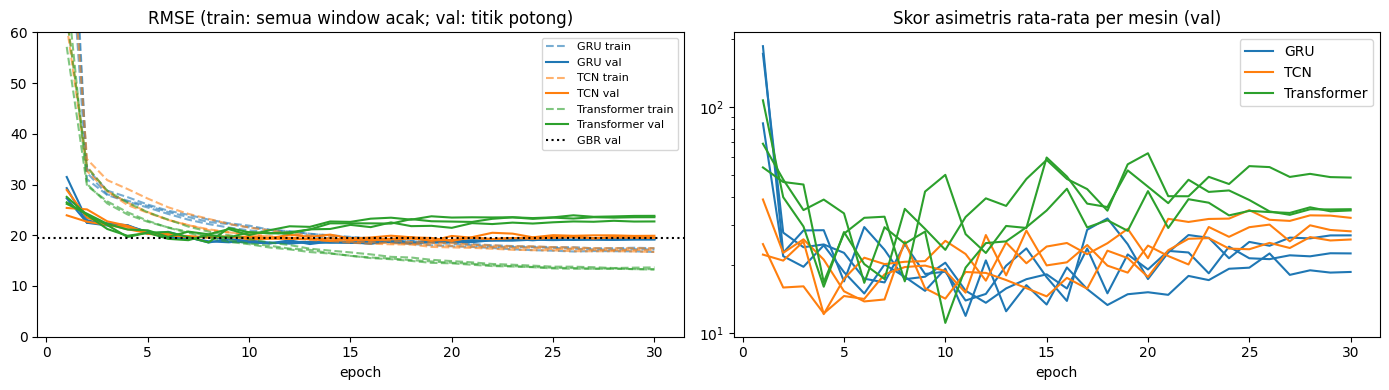

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for i, a in enumerate(ARCHS):
    for s in CMP_SEEDS:
        h = HISTS[(a, s)]
        ax[0].plot(h.epoch, h.train_RMSE, '--', color=f'C{i}', alpha=.6, label=f'{a} train' if s == CMP_SEEDS[0] else None)
        ax[0].plot(h.epoch, h.val_RMSE, color=f'C{i}', label=f'{a} val' if s == CMP_SEEDS[0] else None)
        ax[1].plot(h.epoch, h.val_score, color=f'C{i}', label=a if s == CMP_SEEDS[0] else None)
ax[0].axhline(RES['baseline_GBR']['RMSE'], color='k', ls=':', label='GBR val'); ax[0].set_ylim(0, 60)
ax[0].set_title('RMSE (train: semua window acak; val: titik potong)'); ax[0].set_xlabel('epoch'); ax[0].legend(fontsize=8)
ax[1].set_title('Skor asimetris rata-rata per mesin (val)'); ax[1].set_xlabel('epoch'); ax[1].set_yscale('log'); ax[1].legend()
plt.tight_layout(); plt.show()

,RMSE,score_rata2,score_per300,bias,"RMSE[0,30]","score[0,30]","RMSE[30,60]","score[30,60]","RMSE[60,100]","score[60,100]","RMSE[100,150]","score[100,150]"
baseline_GBR,19.53,24.97,7490.56,3.24,9.83,1.63,18.04,64.54,30.69,65.47,15.63,4.01
GRU,18.94,20.25,6074.08,2.93,9.70,1.63,15.40,40.56,30.29,58.51,15.32,4.07
TCN,19.26,27.08,8125.22,4.68,14.81,3.88,16.97,96.42,29.09,53.43,15.42,3.96
Transformer,21.31,27.63,8290.24,1.49,8.77,1.37,15.99,33.76,31.26,88.66,19.98,7.98


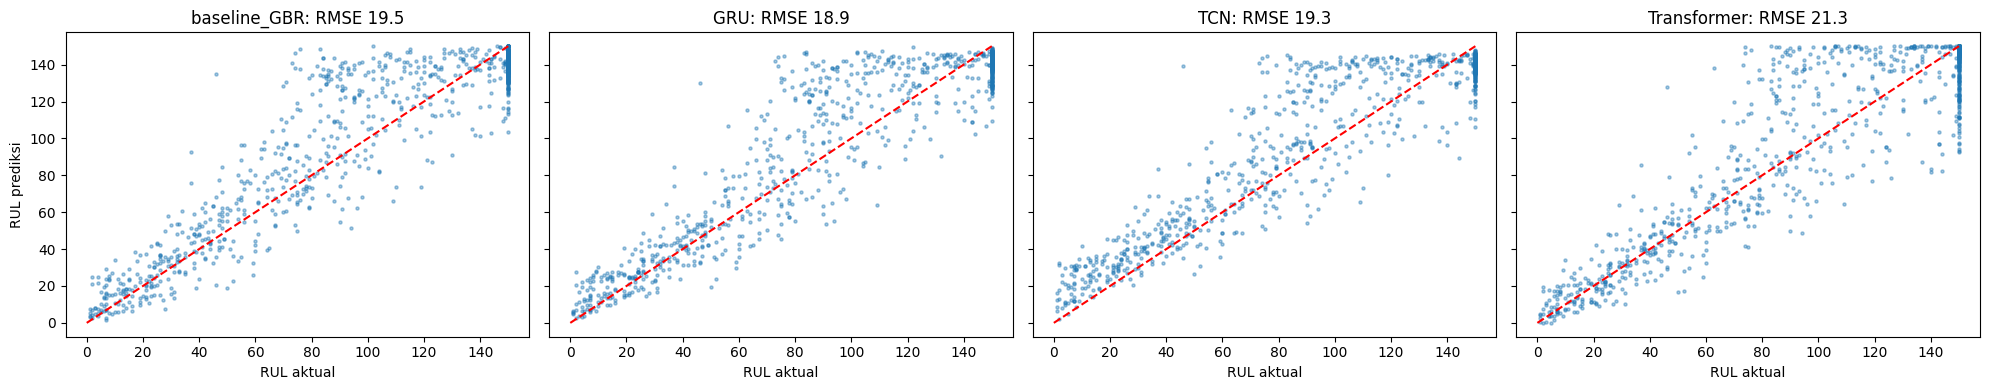

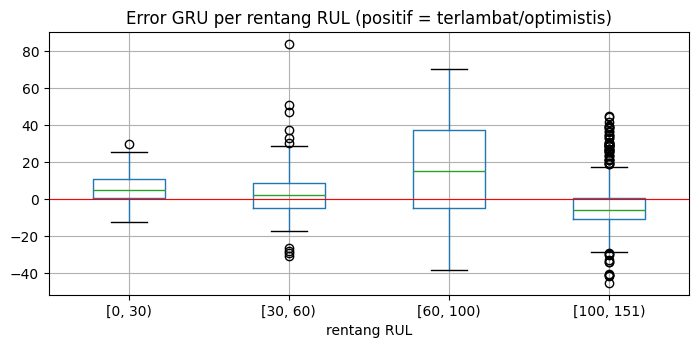

In [20]:
PRED_MEAN = {'baseline_GBR': pred_gb, **{a: np.mean(PRED_CMP[a], 0) for a in ARCHS}}
rng_tab = pd.DataFrame({k: metrics(v, y_cuts) for k, v in PRED_MEAN.items()}).T
display(rng_tab.style.format('{:.2f}'))

fig, ax = plt.subplots(1, len(PRED_MEAN), figsize=(5 * len(PRED_MEAN), 4), sharey=True)
for a_, (k, v) in zip(ax, PRED_MEAN.items()):
    a_.scatter(y_cuts, v, s=5, alpha=.4); a_.plot([0, 150], [0, 150], 'r--')
    a_.set_title(f'{k}: RMSE {metrics(v, y_cuts)["RMSE"]:.1f}'); a_.set_xlabel('RUL aktual')
ax[0].set_ylabel('RUL prediksi'); plt.tight_layout(); plt.show()

err = PRED_MEAN[BEST] - y_cuts
b = pd.cut(y_cuts, [0, 30, 60, 100, 151], right=False)
pd.DataFrame({'error': err, 'rentang RUL': b}).boxplot(column='error', by='rentang RUL', figsize=(8, 3.5))
plt.axhline(0, color='r', lw=.8); plt.title(f'Error {BEST} per rentang RUL (positif = terlambat/optimistis)'); plt.suptitle(''); plt.show()

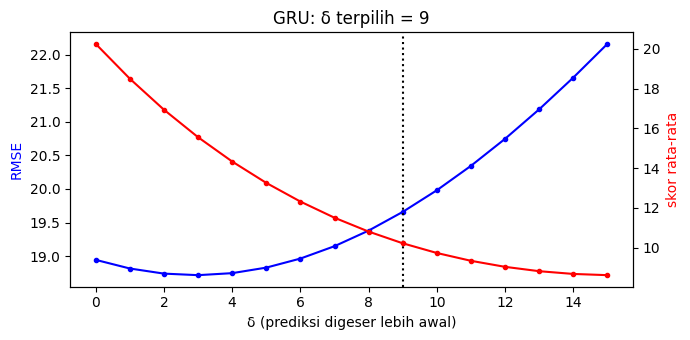

delta=9: RMSE 18.94 -> 19.66, skor rata-rata 20.247 -> 10.215


In [21]:
deltas = np.arange(0, 16)
base = PRED_MEAN[BEST]
rm = [metrics(base - dlt, y_cuts)['RMSE'] for dlt in deltas]
sc = [metrics(base - dlt, y_cuts)['score_rata2'] for dlt in deltas]
ok = [d_ for d_, r_ in zip(deltas, rm) if r_ <= 1.05 * rm[0]]
DELTA = int(min(ok, key=lambda d_: sc[list(deltas).index(d_)]))
fig, ax = plt.subplots(figsize=(7, 3.5)); ax2 = ax.twinx()
ax.plot(deltas, rm, 'b-o', ms=3); ax.set_ylabel('RMSE', color='b'); ax2.plot(deltas, sc, 'r-o', ms=3); ax2.set_ylabel('skor rata-rata', color='r')
ax.axvline(DELTA, color='k', ls=':'); ax.set_xlabel('δ (prediksi digeser lebih awal)'); ax.set_title(f'{BEST}: δ terpilih = {DELTA}')
plt.tight_layout(); plt.show()
print(f'delta={DELTA}: RMSE {rm[0]:.2f} -> {rm[DELTA]:.2f}, skor rata-rata {sc[0]:.3f} -> {sc[DELTA]:.3f}')

,interval mentah (P5-P95),interval terkalibrasi (x2.52)
cakupan (target 90%),0.336,0.918
lebar rata-rata,25.162,58.563


Metrik ensemble (mean): {'RMSE': 19.903, 'score_rata2': 10.681, 'score_per300': 3204.334, 'bias': -6.201}


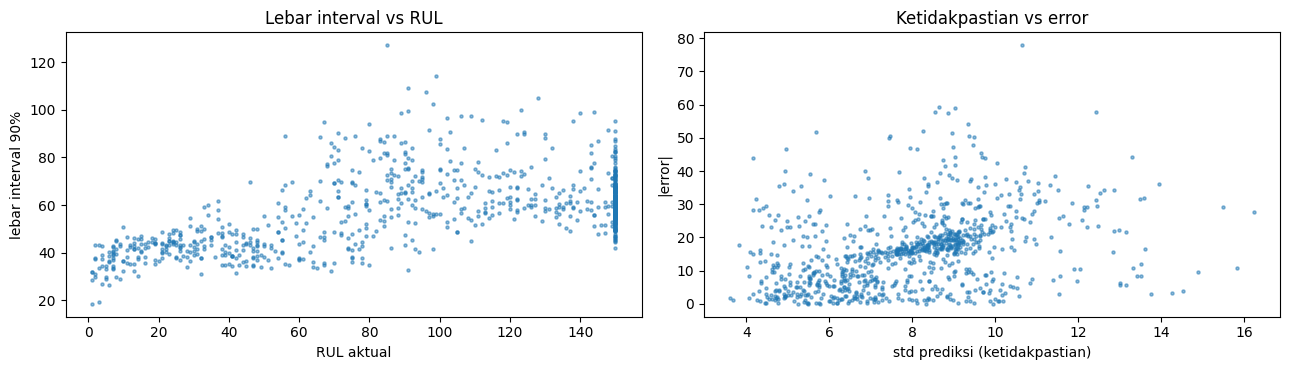

Korelasi Spearman std vs |error|: 0.407


In [22]:
ens_models = [MODELS[(BEST, s)] for s in CMP_SEEDS]
for s in range(len(CMP_SEEDS), N_ENS):
    m, _ = train_model(BEST, D_val, rows_tr, seed=s, val=None, verbose=False)
    ens_models.append(m)
samples = np.concatenate([predict(m, D_val, cuts_va, mc=MC_T) for m in ens_models], 0) - DELTA
samples = np.clip(samples, 0, RUL_CAP)
mu_u = samples.mean(0)
lo_u, hi_u = np.percentile(samples, 5, 0), np.percentile(samples, 95, 0)
RES[f'{BEST}_ensemble{N_ENS}_MC'] = metrics(mu_u, y_cuts)

cut_units = UNIT_all[cuts_va]
cal_units = units_va[::2]
cal = np.isin(cut_units, cal_units); evl = ~cal
def nonconf(lo, hi, mu, y):
    return np.maximum((mu - y) / np.maximum(mu - lo, 1e-3), (y - mu) / np.maximum(hi - mu, 1e-3))
q = np.quantile(nonconf(lo_u[cal], hi_u[cal], mu_u[cal], y_cuts[cal]), 0.9)
lo_c = np.clip(mu_u - q * (mu_u - lo_u), 0, RUL_CAP); hi_c = np.clip(mu_u + q * (hi_u - mu_u), 0, RUL_CAP)
cov = lambda lo, hi, m: float(((y_cuts[m] >= lo[m]) & (y_cuts[m] <= hi[m])).mean())
unc = pd.DataFrame({
    'interval mentah (P5-P95)': {'cakupan (target 90%)': cov(lo_u, hi_u, evl), 'lebar rata-rata': float((hi_u - lo_u)[evl].mean())},
    f'interval terkalibrasi (x{q:.2f})': {'cakupan (target 90%)': cov(lo_c, hi_c, evl), 'lebar rata-rata': float((hi_c - lo_c)[evl].mean())}})
display(unc.round(3))
print('Metrik ensemble (mean):', {k: round(v, 3) for k, v in list(RES[f"{BEST}_ensemble{N_ENS}_MC"].items())[:4]})

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].scatter(y_cuts, hi_c - lo_c, s=5, alpha=.5); ax[0].set_xlabel('RUL aktual'); ax[0].set_ylabel('lebar interval 90%'); ax[0].set_title('Lebar interval vs RUL')
ax[1].scatter(samples.std(0), np.abs(mu_u - y_cuts), s=5, alpha=.5); ax[1].set_xlabel('std prediksi (ketidakpastian)'); ax[1].set_ylabel('|error|')
ax[1].set_title('Ketidakpastian vs error'); plt.tight_layout(); plt.show()
print('Korelasi Spearman std vs |error|:', round(pd.Series(samples.std(0)).corr(pd.Series(np.abs(mu_u - y_cuts)), method='spearman'), 3))

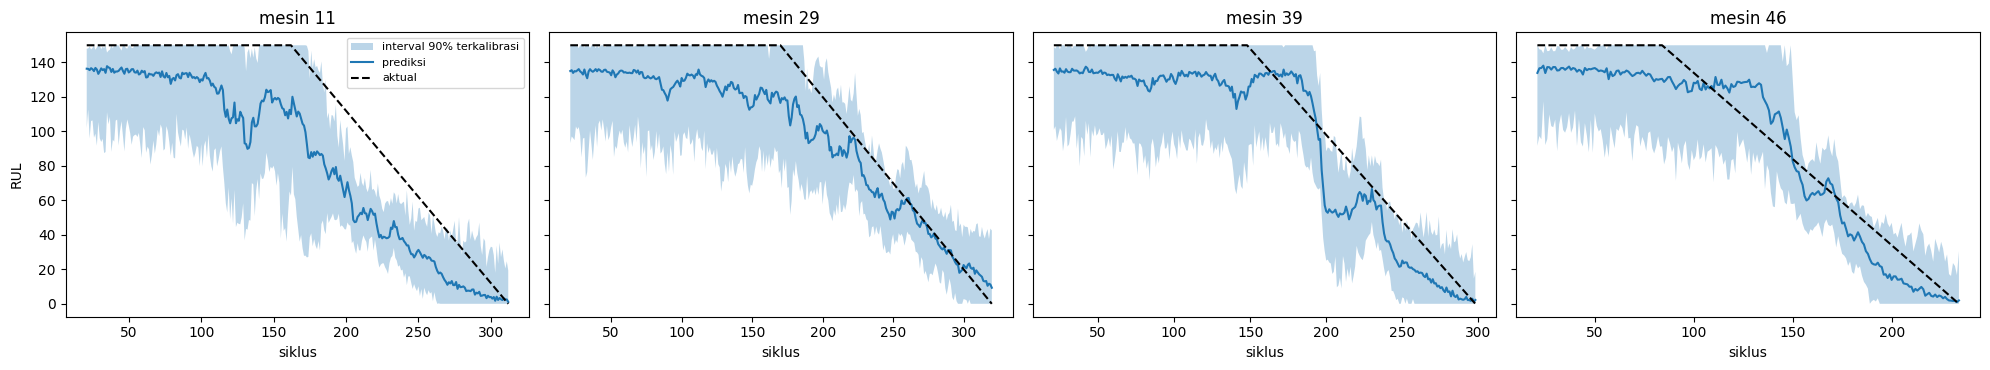

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for a_, uid in zip(ax, units_va[:4]):
    rows = np.where(UNIT_all == uid)[0]; rows = rows[rows >= rows[0] + 20]
    smp = np.clip(np.concatenate([predict(m, D_val, rows, mc=max(5, MC_T // 3)) for m in ens_models], 0) - DELTA, 0, RUL_CAP)
    mu_, lo_, hi_ = smp.mean(0), np.percentile(smp, 5, 0), np.percentile(smp, 95, 0)
    lo_ = np.clip(mu_ - q * (mu_ - lo_), 0, RUL_CAP); hi_ = np.clip(mu_ + q * (hi_ - mu_), 0, RUL_CAP)
    cyc = tr.siklus.values[rows]
    a_.fill_between(cyc, lo_, hi_, alpha=.3, label='interval 90% terkalibrasi'); a_.plot(cyc, mu_, label='prediksi'); a_.plot(cyc, Y_all[rows], 'k--', label='aktual')
    a_.set_title(f'mesin {uid}'); a_.set_xlabel('siklus')
ax[0].set_ylabel('RUL'); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [24]:
pol = []
for H in [10, 20, 30]:
    risk = y_cuts <= H
    for nm, val in [('prediksi titik', mu_u), ('batas bawah 90%', lo_c)]:
        act = val <= H
        pol.append({'H': H, 'aturan': nm, 'recall mesin berisiko': act[risk].mean() if risk.any() else np.nan,
                    'servis terlalu dini (RUL>2H)': (y_cuts[act] > 2 * H).mean() if act.any() else 0.0,
                    'jumlah servis': int(act.sum()), 'jumlah berisiko': int(risk.sum())})
display(pd.DataFrame(pol).set_index(['H', 'aturan']).round(3))

recall mesin berisiko  servis terlalu dini (RUL>2H)  \
H  aturan                                                                 
10 prediksi titik                   0.714                         0.143   
   batas bawah 90%                  1.000                         0.485   
20 prediksi titik                   0.966                         0.016   
   batas bawah 90%                  1.000                         0.186   
30 prediksi titik                   0.943                         0.000   
   batas bawah 90%                  1.000                         0.076   

                    jumlah servis  jumlah berisiko  
H  aturan                                           
10 prediksi titik              63               49  
   batas bawah 90%            171               49  
20 prediksi titik             122               88  
   batas bawah 90%            215               88  
30 prediksi titik             165              140  
   batas bawah 90%            262              140

lonjakan diganti di test: 656 | mesin uji: 300
  [final_GRU s1000] ep  1 train_RMSE=85.62 (1s)
  [final_GRU s1000] ep 10 train_RMSE=20.42 (6s)
  [final_GRU s1000] ep 20 train_RMSE=17.90 (11s)
  [final_GRU s1000] ep 30 train_RMSE=16.91 (17s)
  [final_GRU s1001] ep  1 train_RMSE=97.61 (1s)
  [final_GRU s1001] ep 10 train_RMSE=21.28 (5s)
  [final_GRU s1001] ep 20 train_RMSE=18.04 (11s)
  [final_GRU s1001] ep 30 train_RMSE=17.23 (17s)
  [final_GRU s1002] ep  1 train_RMSE=87.32 (1s)
  [final_GRU s1002] ep 10 train_RMSE=20.52 (6s)
  [final_GRU s1002] ep 20 train_RMSE=17.84 (11s)
  [final_GRU s1002] ep 30 train_RMSE=17.13 (17s)
  [final_GRU s1003] ep  1 train_RMSE=99.52 (1s)
  [final_GRU s1003] ep 10 train_RMSE=20.91 (6s)
  [final_GRU s1003] ep 20 train_RMSE=18.03 (11s)
  [final_GRU s1003] ep 30 train_RMSE=17.31 (17s)
  [final_GRU s1004] ep  1 train_RMSE=83.84 (1s)
  [final_GRU s1004] ep 10 train_RMSE=20.19 (5s)
  [final_GRU s1004] ep 20 train_RMSE=17.69 (11s)
  [final_GRU s1004] ep 30 train_

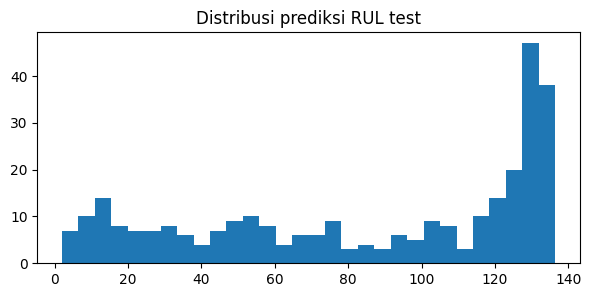

In [25]:
P_full = fit_prep(tr)
P_full['sel'] = P_val['sel']
X_full, START_full, _ = transform(tr, P_full)
X_test, START_test, nsp_te = transform(te, P_full)
assert X_full.shape[1] == N_FEAT == X_test.shape[1], 'jumlah sensor terpilih berubah; samakan P_full["sel"] dengan P_val["sel"]'
D_full = to_dev(X_full, START_full, Y_all)
D_test = to_dev(X_test, START_test)
last_te = te.groupby('id_unit').tail(1).index.values
print('lonjakan diganti di test:', nsp_te, '| mesin uji:', len(last_te))

final_models, test_samples = [], []
for s in range(N_ENS):
    m, _ = train_model(BEST, D_full, np.arange(len(X_full)), seed=1000 + s, verbose=True, tag=f'final_{BEST}')
    torch.save(m.state_dict(), f'{OUT_DIR}/rul_{BEST}_seed{1000+s}.pt')
    test_samples.append(predict(m, D_test, last_te, mc=MC_T))
    final_models.append(m)
ts = np.clip(np.concatenate(test_samples, 0) - DELTA, 0, RUL_CAP)
rul_pred = np.clip(ts.mean(0), 0, RUL_CAP)
t_lo, t_hi = np.percentile(ts, 5, 0), np.percentile(ts, 95, 0)
t_lo = np.clip(rul_pred - q * (rul_pred - t_lo), 0, RUL_CAP); t_hi = np.clip(rul_pred + q * (t_hi - rul_pred), 0, RUL_CAP)

sub = pd.DataFrame({'id_unit': te.loc[last_te, 'id_unit'].values, 'rul': np.round(rul_pred, 2)})
assert len(sub) == te.id_unit.nunique() and sub.id_unit.is_unique and sub.rul.between(0, 150).all()
sub.to_csv(f'{OUT_DIR}/prediksi_rul.csv', index=False)
pd.DataFrame({'id_unit': sub.id_unit, 'rul': sub.rul, 'pi90_bawah': t_lo.round(2), 'pi90_atas': t_hi.round(2),
              'servis_disarankan_H20': (t_lo <= 20)}).to_csv(f'{OUT_DIR}/rul_interval_test.csv', index=False)
json.dump({'arch': BEST, 'cfg': CFG, 'delta': DELTA, 'calib_q': float(q), 'n_ens': N_ENS, 'mc_T': MC_T,
           'sensors': P_full['sel'], 'regimes': REG_MAP}, open(f'{OUT_DIR}/rul_config.json', 'w'), indent=2)
print(sub.head()); print(sub.rul.describe().round(2))
plt.figure(figsize=(7, 3)); plt.hist(sub.rul, bins=30); plt.title('Distribusi prediksi RUL test'); plt.show()

In [26]:
summary = pd.DataFrame(RES).T
display(summary[['RMSE', 'score_rata2', 'score_per300', 'bias']].style.format('{:.3f}'))
summary.to_csv(f'{OUT_DIR}/rul_ringkasan_eksperimen.csv')
try:
    from google.colab import files
    files.download(f'{OUT_DIR}/prediksi_rul.csv')
except Exception as e:
    print('Unduh manual dari panel Files:', e)

,RMSE,score_rata2,score_per300,bias
baseline_GBR,19.528,24.969,7490.561,3.240
GRU_seed0,19.465,18.615,5584.486,2.907
GRU_seed1,19.224,27.034,8110.055,2.970
GRU_seed2,19.163,22.487,6746.244,2.909
TCN_seed0,19.529,28.172,8451.743,3.677
TCN_seed1,19.902,25.917,7775.018,5.595
TCN_seed2,19.487,32.323,9696.800,4.769
Transformer_seed0,23.561,48.724,14617.328,1.197
Transformer_seed1,23.826,34.851,10455.400,1.485
Transformer_seed2,22.722,35.294,10588.239,1.793


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>